# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Mufti Akbar
- NIM   : 241011401908
- Kelas : Reg B 

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda**. Untuk NIM `241011401908`, dua digit terakhir adalah `08`, yang ditulis sebagai bilangan bulat `8` di Python (agar tidak menjadi literal oktal). Karena itu, `RANDOM_STATE = 8`.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [ ]:
# Import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Dua digit terakhir NIM adalah 08; nilai integer Python ditulis 8.
RANDOM_STATE = 8
np.set_printoptions(precision=4, suppress=True)


In [ ]:
# Pembagian data manual dengan pola yang sama seperti materi.
def train_test_split(X, y, test_size=0.25, random_state=None):
    X = np.asarray(X)
    y = np.asarray(y)
    if len(X) != len(y):
        raise ValueError("X dan y harus memiliki jumlah baris yang sama.")
    if not 0 < test_size < 1:
        raise ValueError("test_size harus berada di antara 0 dan 1.")
    n_test = int(round(len(X) * test_size))
    if n_test < 1 or n_test >= len(X):
        raise ValueError("Ukuran data testing tidak valid.")
    rng = np.random.RandomState(random_state) if random_state is not None else np.random
    indices = rng.permutation(len(X))
    test_idx, train_idx = indices[:n_test], indices[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]


class LinearRegression:
    """Linear Regression manual menggunakan Normal Equation."""
    def __init__(self):
        self.intercept_ = 0.0
        self.coefficients_ = None

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        X_b = np.c_[np.ones(len(X)), X]
        beta = np.linalg.pinv(X_b.T @ X_b) @ X_b.T @ y
        self.intercept_, self.coefficients_ = beta[0], beta[1:]
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        return self.intercept_ + X @ self.coefficients_


class LinearRegressionGD:
    """Linear Regression manual dengan Gradient Descent dan riwayat MSE."""
    def __init__(self, learning_rate=0.02, n_iterations=5000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coefficients_ = None
        self.loss_history_ = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])
        self.loss_history_ = []
        with np.errstate(over="ignore", invalid="ignore"):
            for _ in range(self.n_iterations):
                y_hat = X_b @ beta
                gradient = X_b.T @ (y_hat - y) / len(y)
                beta = beta - self.learning_rate * gradient
                residual = y - X_b @ beta
                loss = np.mean(residual ** 2)
                self.loss_history_.append(float(loss))
                if not np.all(np.isfinite(beta)) or not np.isfinite(loss):
                    break
        self.intercept_, self.coefficients_ = beta[0], beta[1:]
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        return self.intercept_ + X @ self.coefficients_


class LogisticRegression:
    """Logistic Regression biner manual dengan Gradient Descent."""
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coefficients_ = None
        self.loss_history_ = []

    @staticmethod
    def _sigmoid(z):
        z = np.asarray(z, dtype=float)
        # Implementasi stabil agar exp tidak overflow untuk nilai ekstrem.
        out = np.empty_like(z)
        pos = z >= 0
        out[pos] = 1 / (1 + np.exp(-z[pos]))
        exp_z = np.exp(z[~pos])
        out[~pos] = exp_z / (1 + exp_z)
        return out

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])
        self.loss_history_ = []
        for _ in range(self.n_iterations):
            p = self._sigmoid(X_b @ beta)
            gradient = X_b.T @ (p - y) / len(y)
            beta -= self.learning_rate * gradient
            p_after = np.clip(self._sigmoid(X_b @ beta), 1e-15, 1 - 1e-15)
            loss = -np.mean(y * np.log(p_after) + (1 - y) * np.log(1 - p_after))
            self.loss_history_.append(float(loss))
        self.intercept_, self.coefficients_ = beta[0], beta[1:]
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        return self._sigmoid(self.intercept_ + X @ self.coefficients_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)


def accuracy_score(y_true, y_pred):
    return float(np.mean(np.asarray(y_true) == np.asarray(y_pred)))


def confusion_matrix(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[tn, fp], [fn, tp]])


def precision_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return float(tp / (tp + fp)) if tp + fp else 0.0


def recall_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return float(tp / (tp + fn)) if tp + fn else 0.0


def f1_score(y_true, y_pred):
    p, r = precision_score(y_true, y_pred), recall_score(y_true, y_pred)
    return float(2 * p * r / (p + r)) if p + r else 0.0


def regression_metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    mae = np.mean(np.abs(y_true - y_pred))
    mse = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    denominator = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1 - np.sum((y_true - y_pred) ** 2) / denominator if denominator else np.nan
    return mae, mse, rmse, r2


---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris data: 40
Shape X: (40, 1) | Shape y: (40,)


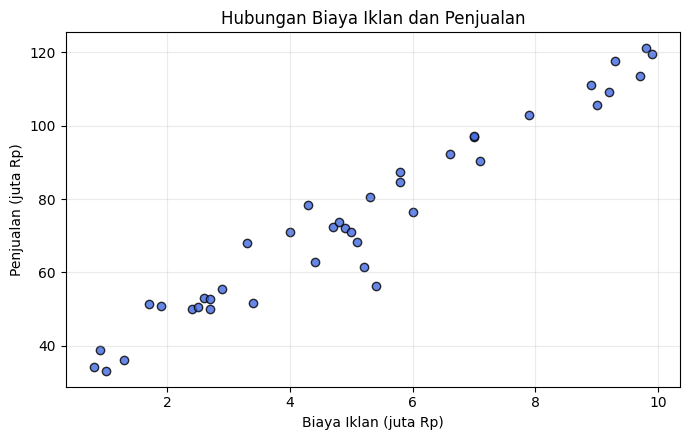

In [ ]:
# A1 — membaca data, memeriksa bentuk fitur, dan visualisasi
ads_data = pd.read_csv("Ads_Data.csv")
display(ads_data.head())
print(f"Jumlah baris data: {len(ads_data)}")
X = ads_data[["BiayaIklan"]].to_numpy(dtype=float)
y = ads_data["Penjualan"].to_numpy(dtype=float)
print("Shape X:", X.shape, "| Shape y:", y.shape)

plt.figure(figsize=(7, 4.5))
plt.scatter(X[:, 0], y, color="royalblue", edgecolor="black", alpha=0.8)
plt.title("Hubungan Biaya Iklan dan Penjualan")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [ ]:
# A2 — pembagian data 80% training dan 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)


X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [ ]:
# A3 — training Linear Regression dengan Normal Equation
regressor = LinearRegression().fit(X_train, y_train)
print(f"Intercept (b): {regressor.intercept_:.6f}")
print(f"Koefisien (m): {regressor.coefficients_[0]:.6f}")
print(f"Persamaan: ŷ = {regressor.intercept_:.4f} + ({regressor.coefficients_[0]:.4f} × BiayaIklan)")


Intercept (b): 28.994498
Koefisien (m): 9.068807
Persamaan: ŷ = 28.9945 + (9.0688 × BiayaIklan)


**Jawaban A3 (interpretasi):**

Persamaan garis yang diperoleh adalah **ŷ = 28,9945 + 9,0688 × BiayaIklan**. Artinya, berdasarkan data training, setiap kenaikan biaya iklan sebesar Rp1 juta berkaitan dengan kenaikan prediksi penjualan sekitar Rp9,07 juta. Ini menunjukkan hubungan positif pada dataset, tetapi bukan bukti bahwa kenaikan iklan selalu menyebabkan penjualan naik sebesar itu dalam semua kondisi.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [ ]:
# A4 — metrik evaluasi manual dengan NumPy
y_train_pred = regressor.predict(X_train)
y_test_pred = regressor.predict(X_test)
metrics_train = regression_metrics(y_train, y_train_pred)
metrics_test = regression_metrics(y_test, y_test_pred)
regression_results = pd.DataFrame(
    [metrics_train, metrics_test],
    index=["Training", "Testing"],
    columns=["MAE", "MSE", "RMSE", "R²"]
)
display(regression_results.round(4))


,MAE,MSE,RMSE,R²
Training,4.2685,28.2835,5.3182,0.9493
Testing,5.3610,68.6741,8.2870,0.9154


**Jawaban A4 (analisis):**

Pada data testing, RMSE sebesar **8,287 juta Rp** berarti rata-rata besar kesalahan prediksi dalam satuan penjualan sekitar Rp8,29 juta (RMSE memberi bobot lebih besar pada kesalahan besar). Nilai **R² = 0,9154** menunjukkan model menjelaskan sekitar 91,54% variasi penjualan pada data testing. Hasil ini cukup baik untuk dataset ini, tetapi jumlah data hanya 40 sehingga performa tetap perlu diuji dengan data yang lebih banyak.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

,Learning rate,Intercept akhir,Koefisien akhir,Iterasi tercatat,Loss akhir (MSE),Status
0,0.001,20.0333,10.5544,5000,46.3321,Stabil
1,0.020,28.9945,9.06881,5000,28.2835,Stabil
2,0.100,-1.08474e+152,-6.54308e+152,526,3.43017e+306,Divergen / nilai non-finite


Normal Equation: b=28.994498, m=9.068807


/opt/pyvenv/lib/python3.13/site-packages/matplotlib/scale.py:270: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


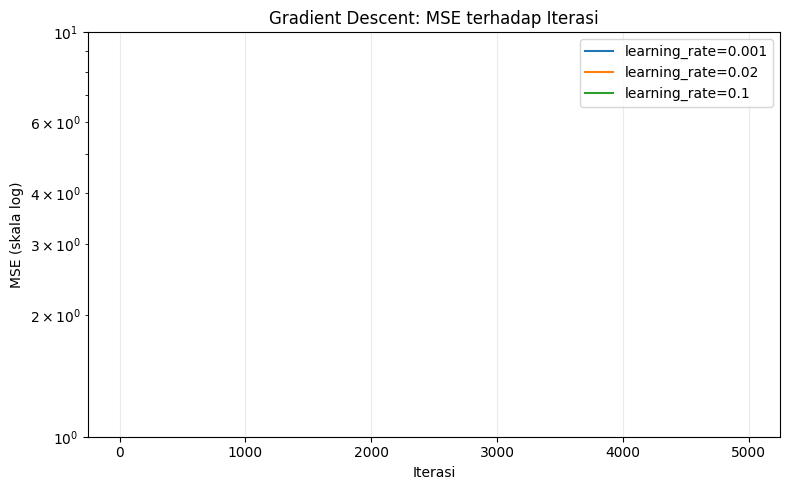

In [ ]:
# A5 — eksperimen Gradient Descent untuk tiga learning rate
learning_rates = [0.001, 0.02, 0.1]
gd_models = {}
gd_rows = []
for lr in learning_rates:
    model = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train, y_train)
    gd_models[lr] = model
    losses = np.asarray(model.loss_history_, dtype=float)
    finite_losses = losses[np.isfinite(losses)]
    converged = len(finite_losses) == 5000 and np.all(np.isfinite(model.coefficients_))
    gd_rows.append({
        "Learning rate": lr,
        "Intercept akhir": f"{model.intercept_:.6g}",
        "Koefisien akhir": f"{model.coefficients_[0]:.6g}",
        "Iterasi tercatat": len(losses),
        "Loss akhir (MSE)": f"{finite_losses[-1]:.6g}" if len(finite_losses) else "non-finite",
        "Status": "Stabil" if converged else "Divergen / nilai non-finite"
    })
gd_results = pd.DataFrame(gd_rows)
display(gd_results)
print(f"Normal Equation: b={regressor.intercept_:.6f}, m={regressor.coefficients_[0]:.6f}")

plt.figure(figsize=(8, 5))
for lr, model in gd_models.items():
    losses = np.asarray(model.loss_history_, dtype=float)
    valid = np.isfinite(losses) & (losses > 0)
    if valid.any():
        plt.plot(np.arange(1, len(losses) + 1)[valid], losses[valid], label=f"learning_rate={lr}")
plt.yscale("log")
plt.xlabel("Iterasi")
plt.ylabel("MSE (skala log)")
plt.title("Gradient Descent: MSE terhadap Iterasi")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


**Jawaban A5 (analisis):**

Learning rate **0,001** masih stabil, tetapi setelah 5.000 iterasi MSE-nya sekitar **46,3321** dan parameternya belum mendekati Normal Equation, sehingga proses belajarnya relatif lambat. Learning rate **0,02** mencapai MSE sekitar **28,2835** dan parameter hampir sama dengan Normal Equation (intercept 28,9945 dan koefisien 9,0688), sehingga paling sesuai dari tiga percobaan. Learning rate **0,1** divergen: nilai parameter membesar dan loss menjadi non-finite sebelum 5.000 iterasi. Langkah pembaruan yang terlalu besar membuat model melewati titik minimum dan kesalahan terus membesar.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

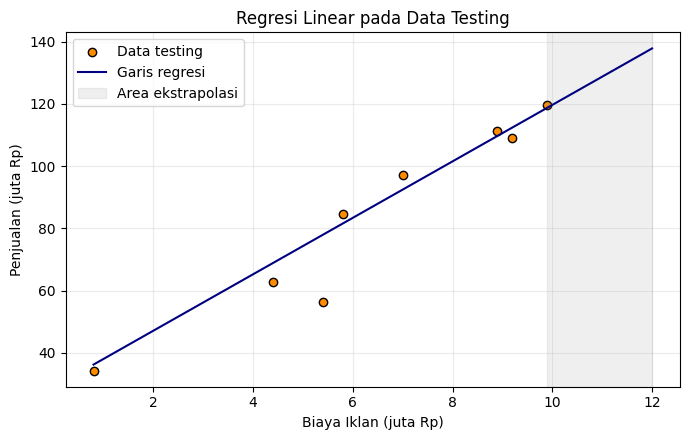

,Biaya Iklan (juta Rp),Prediksi Penjualan (juta Rp)
0,4.5,69.8041
1,7.0,92.4761
2,12.0,137.8202


In [ ]:
# A6 — visualisasi garis regresi dan prediksi biaya iklan baru
plt.figure(figsize=(7, 4.5))
plt.scatter(X_test[:, 0], y_test, color="darkorange", edgecolor="black", label="Data testing")
x_line = np.linspace(float(X.min()), 12, 200).reshape(-1, 1)
plt.plot(x_line[:, 0], regressor.predict(x_line), color="navy", label="Garis regresi")
plt.axvspan(float(X.max()), 12, color="gray", alpha=0.12, label="Area ekstrapolasi")
plt.title("Regresi Linear pada Data Testing")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

biaya_baru = np.array([[4.5], [7.0], [12.0]])
prediksi_penjualan = regressor.predict(biaya_baru)
display(pd.DataFrame({"Biaya Iklan (juta Rp)": biaya_baru[:, 0],
                      "Prediksi Penjualan (juta Rp)": prediksi_penjualan}).round(4))


**Jawaban A6 (analisis):**

Prediksi penjualan untuk biaya iklan Rp4,5 juta, Rp7 juta, dan Rp12 juta masing-masing sekitar **Rp69,8041 juta**, **Rp92,4761 juta**, dan **Rp137,8202 juta**. Prediksi Rp12 juta merupakan ekstrapolasi karena berada di luar rentang biaya iklan pada dataset. Karena model mengasumsikan hubungan linear yang sama terus berlaku, hasil pada Rp12 juta lebih tidak pasti dan sebaiknya dipakai sebagai perkiraan awal saja, bukan jaminan penjualan.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah baris data: 60
Jumlah Bukan Spam (0): 35
Jumlah Spam (1): 25
Shape X: (60, 2) | Shape y: (60,)


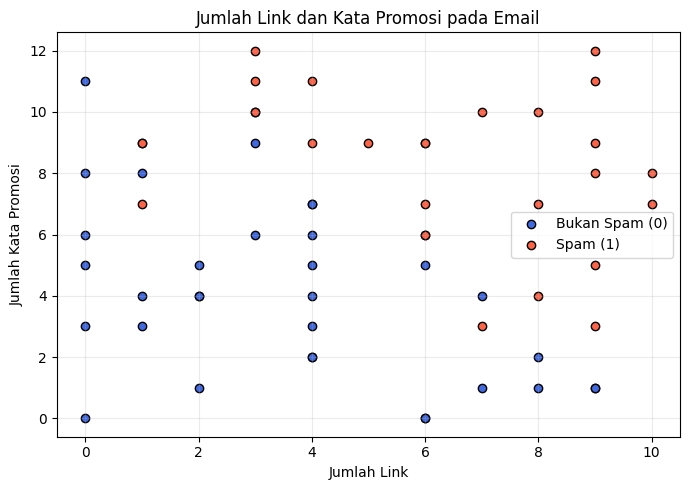

In [ ]:
# B1 — membaca data email dan visualisasi kelas
email_data = pd.read_csv("Email_Data.csv")
display(email_data.head())
print("Jumlah baris data:", len(email_data))
print("Jumlah Bukan Spam (0):", int((email_data["Spam"] == 0).sum()))
print("Jumlah Spam (1):", int((email_data["Spam"] == 1).sum()))
X_email = email_data[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
y_email = email_data["Spam"].to_numpy(dtype=int)
print("Shape X:", X_email.shape, "| Shape y:", y_email.shape)

plt.figure(figsize=(7, 5))
plt.scatter(X_email[y_email == 0, 0], X_email[y_email == 0, 1],
            color="royalblue", edgecolor="black", label="Bukan Spam (0)")
plt.scatter(X_email[y_email == 1, 0], X_email[y_email == 1, 1],
            color="tomato", edgecolor="black", label="Spam (1)")
plt.title("Jumlah Link dan Kata Promosi pada Email")
plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promosi")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

X_train: (45, 2) | X_test: (15, 2)
y_train: (45,) | y_test: (15,)


Intercept (b): -8.433788
Koefisien (m1, m2): (0.761171, 0.725520)
P(Spam) = sigmoid(-8.4338 + (0.7612 × JumlahLink) + (0.7255 × KataPromo))


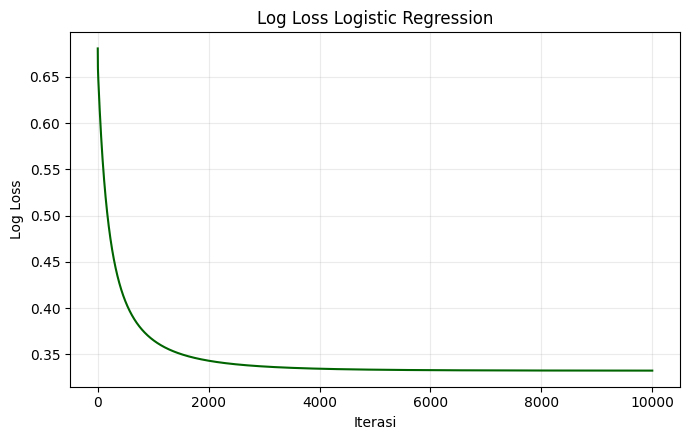

Log loss awal: 0.680726
Log loss akhir: 0.332354


In [ ]:
# B2 — split data dan training Logistic Regression manual
X_train_email, X_test_email, y_train_email, y_test_email = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)
print("X_train:", X_train_email.shape, "| X_test:", X_test_email.shape)
print("y_train:", y_train_email.shape, "| y_test:", y_test_email.shape)

classifier = LogisticRegression(learning_rate=0.1, n_iterations=10000)
classifier.fit(X_train_email, y_train_email)
b = classifier.intercept_
m1, m2 = classifier.coefficients_
print(f"Intercept (b): {b:.6f}")
print(f"Koefisien (m1, m2): ({m1:.6f}, {m2:.6f})")
print(f"P(Spam) = sigmoid({b:.4f} + ({m1:.4f} × JumlahLink) + ({m2:.4f} × KataPromo))")

plt.figure(figsize=(7, 4.5))
plt.plot(np.arange(1, len(classifier.loss_history_) + 1), classifier.loss_history_, color="darkgreen")
plt.xlabel("Iterasi")
plt.ylabel("Log Loss")
plt.title("Log Loss Logistic Regression")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()
print(f"Log loss awal: {classifier.loss_history_[0]:.6f}")
print(f"Log loss akhir: {classifier.loss_history_[-1]:.6f}")


**Jawaban B2 (analisis):**

Model menghasilkan persamaan **P(Spam) = sigmoid(-8,4338 + 0,7612 × JumlahLink + 0,7255 × KataPromo)**. Koefisien kedua fitur bernilai positif, sehingga bertambahnya jumlah link atau kata promosi menaikkan probabilitas spam ketika fitur lain dianggap tetap. Log loss turun dari **0,6807** menjadi **0,3324** selama 10.000 iterasi, yang menunjukkan prediksi probabilitas membaik dan proses training berjalan stabil.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [ ]:
# B3 — evaluasi testing menggunakan fungsi metrik manual
y_pred_email = classifier.predict(X_test_email, threshold=0.5)
cm_email = confusion_matrix(y_test_email, y_pred_email)
tn, fp, fn, tp = cm_email.ravel()
metrics_email = pd.DataFrame([{
    "Accuracy": accuracy_score(y_test_email, y_pred_email),
    "Precision": precision_score(y_test_email, y_pred_email),
    "Recall": recall_score(y_test_email, y_pred_email),
    "F1-score": f1_score(y_test_email, y_pred_email)
}], index=["Testing"])
display(metrics_email.round(4))
print("Confusion matrix (baris=aktual [0,1], kolom=prediksi [0,1]):")
print(cm_email)
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")


,Accuracy,Precision,Recall,F1-score
Testing,1.0,1.0,1.0,1.0


Confusion matrix (baris=aktual [0,1], kolom=prediksi [0,1]):
[[12  0]
 [ 0  3]]
TN=12, FP=0, FN=0, TP=3


**Jawaban B3 (analisis):**

Pada data testing diperoleh **accuracy, precision, recall, dan F1-score masing-masing 1,00**, dengan confusion matrix `[[12, 0], [0, 3]]`. Artinya, 12 email bukan spam dan 3 email spam pada data testing semuanya terklasifikasi benar. **FP** adalah email bukan spam yang keliru ditandai spam, sedangkan **FN** adalah email spam yang lolos sebagai bukan spam. Untuk filter spam, FN sering lebih merugikan karena pesan berbahaya dapat masuk ke inbox; namun FP juga mengganggu jika email penting masuk folder spam. Hasil ini perlu ditafsirkan hati-hati karena hanya ada 15 sampel testing.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

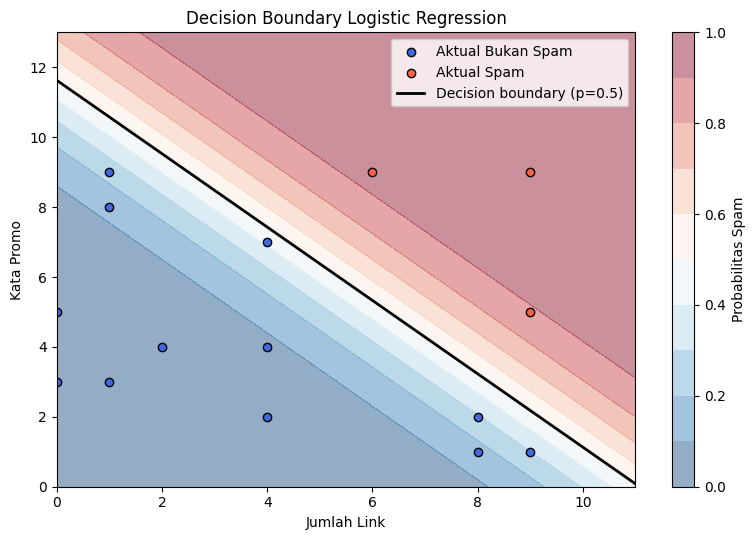

Jumlah data testing yang salah diklasifikasikan: 0
Tidak ada data testing yang salah diklasifikasikan pada threshold 0.5.


In [ ]:
# B4 — background probabilitas, decision boundary, dan data salah klasifikasi
x1_min, x1_max = 0, max(10, int(X_email[:, 0].max()) + 1)
x2_min, x2_max = 0, max(10, int(X_email[:, 1].max()) + 1)
grid_x1, grid_x2 = np.meshgrid(
    np.linspace(x1_min, x1_max, 250),
    np.linspace(x2_min, x2_max, 250)
)
grid_points = np.c_[grid_x1.ravel(), grid_x2.ravel()]
grid_prob = classifier.predict_proba(grid_points).reshape(grid_x1.shape)

plt.figure(figsize=(8, 5.5))
contour = plt.contourf(grid_x1, grid_x2, grid_prob, levels=np.linspace(0, 1, 11),
                       cmap="RdBu_r", alpha=0.45, vmin=0, vmax=1)
plt.colorbar(contour, label="Probabilitas Spam")
plt.scatter(X_test_email[y_test_email == 0, 0], X_test_email[y_test_email == 0, 1],
            color="royalblue", edgecolor="black", label="Aktual Bukan Spam")
plt.scatter(X_test_email[y_test_email == 1, 0], X_test_email[y_test_email == 1, 1],
            color="tomato", edgecolor="black", label="Aktual Spam")
x1_line = np.linspace(x1_min, x1_max, 200)
if abs(m2) > 1e-12:
    x2_line = -(b + m1 * x1_line) / m2
    plt.plot(x1_line, x2_line, color="black", linewidth=2, label="Decision boundary (p=0.5)")
misclassified = y_pred_email != y_test_email
if np.any(misclassified):
    plt.scatter(X_test_email[misclassified, 0], X_test_email[misclassified, 1],
                s=180, facecolors="none", edgecolors="yellow", linewidths=2.5,
                label="Salah klasifikasi")
plt.xlim(x1_min, x1_max)
plt.ylim(x2_min, x2_max)
plt.xlabel("Jumlah Link")
plt.ylabel("Kata Promo")
plt.title("Decision Boundary Logistic Regression")
plt.legend()
plt.tight_layout()
plt.show()

# Tabel berisi data testing yang salah diklasifikasikan, jika ada.
print("Jumlah data testing yang salah diklasifikasikan:", int(misclassified.sum()))
if np.any(misclassified):
    display(pd.DataFrame({
        "JumlahLink": X_test_email[misclassified, 0].astype(int),
        "KataPromo": X_test_email[misclassified, 1].astype(int),
        "Spam aktual": y_test_email[misclassified],
        "Prediksi": y_pred_email[misclassified],
        "Probabilitas Spam": classifier.predict_proba(X_test_email[misclassified]).round(4)
    }).reset_index(drop=True))
else:
    print("Tidak ada data testing yang salah diklasifikasikan pada threshold 0.5.")


**Jawaban B4 (analisis):**

Decision boundary adalah garis saat probabilitas spam sama dengan 0,5, yaitu `x₂ = -(b + m₁x₁) / m₂`. Pada threshold 0,5, tidak ada data testing yang salah diklasifikasikan, sehingga tidak ada titik yang ditandai sebagai kesalahan pada grafik. Background probabilitas memperlihatkan bahwa kombinasi jumlah link dan kata promosi yang lebih tinggi cenderung diprediksi sebagai spam.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [ ]:
# B5 — bandingkan threshold 0.3, 0.5, dan 0.7
proba_test_email = classifier.predict_proba(X_test_email)
threshold_rows = []
threshold_predictions = {}
for threshold in [0.3, 0.5, 0.7]:
    pred = (proba_test_email >= threshold).astype(int)
    threshold_predictions[threshold] = pred
    cm = confusion_matrix(y_test_email, pred)
    tn_t, fp_t, fn_t, tp_t = cm.ravel()
    threshold_rows.append({
        "Threshold": threshold, "TN": tn_t, "FP": fp_t, "FN": fn_t, "TP": tp_t,
        "Precision": precision_score(y_test_email, pred),
        "Recall": recall_score(y_test_email, pred),
        "Accuracy": accuracy_score(y_test_email, pred)
    })
threshold_results = pd.DataFrame(threshold_rows).set_index("Threshold")
display(threshold_results.round(4))
# Pada hasil aktual, threshold 0.5 mempertahankan recall 1.0 dan precision 1.0,
# sedangkan threshold 0.3 menambah satu false positive tanpa menaikkan recall.
THRESHOLD_PILIHAN = 0.5
print("Threshold pilihan untuk B6:", THRESHOLD_PILIHAN)


,TN,FP,FN,TP,Precision,Recall,Accuracy
Threshold,,,,,,,
0.3,11,1,0,3,0.75,1.0,0.9333
0.5,12,0,0,3,1.00,1.0,1.0000
0.7,12,0,0,3,1.00,1.0,1.0000


Threshold pilihan untuk B6: 0.5


**Jawaban B5 (analisis):**

Threshold **0,3** menghasilkan precision **0,75** dan recall **1,00**, karena satu email bukan spam ikut ditandai spam (FP=1). Threshold **0,5** dan **0,7** sama-sama menghasilkan precision dan recall **1,00** pada data testing ini. Secara umum, menurunkan threshold membuat model lebih mudah menyatakan spam sehingga recall bisa naik, tetapi FP juga dapat bertambah; menaikkan threshold cenderung mengurangi FP tetapi berisiko menambah FN. Berdasarkan hasil aktual, saya memilih threshold **0,5** karena recall tetap 1,00 dan precision lebih tinggi daripada threshold 0,3.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [ ]:
# B6 — prediksi email baru menggunakan threshold pilihan dari B5
email_baru = pd.DataFrame({
    "Email": ["E1", "E2", "E3", "E4"],
    "JumlahLink": [1, 5, 9, 2],
    "KataPromo": [2, 6, 10, 11]
})
X_email_baru = email_baru[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
email_baru["Probabilitas Spam"] = classifier.predict_proba(X_email_baru)
email_baru["Prediksi Spam"] = (email_baru["Probabilitas Spam"] >= THRESHOLD_PILIHAN).astype(int)
email_baru["Keterangan"] = np.where(email_baru["Prediksi Spam"] == 1, "Spam", "Bukan Spam")
display(email_baru.round(4))


,Email,JumlahLink,KataPromo,Probabilitas Spam,Prediksi Spam,Keterangan
0,E1,1,2,0.0020,0,Bukan Spam
1,E2,5,6,0.4317,0,Bukan Spam
2,E3,9,10,0.9966,1,Spam
3,E4,2,11,0.7445,1,Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**

Logistic Regression termasuk klasifikasi karena hasil akhirnya digunakan untuk menentukan kelas, misalnya spam atau bukan spam, bukan untuk memprediksi angka kontinu. Model menghitung kombinasi linear dari fitur, lalu fungsi sigmoid mengubahnya menjadi probabilitas antara 0 dan 1. Probabilitas itu dibandingkan dengan threshold untuk menentukan kelas 0 atau 1.

**Jawaban C2:**

Normal Equation menghitung koefisien secara langsung melalui operasi matriks sehingga tidak membutuhkan iterasi. Gradient Descent memperbarui koefisien sedikit demi sedikit berdasarkan gradien loss. Gradient Descent lebih cocok untuk dataset besar atau banyak fitur ketika perhitungan matriks langsung mahal, tetapi learning rate dan jumlah iterasinya perlu dipilih dengan baik.

**Jawaban C3:**

Data testing dipakai untuk memperkirakan kemampuan model pada data baru yang tidak dipakai saat training. Jika hanya mengukur data training, nilai evaluasi bisa terlihat bagus karena model sudah menyesuaikan diri dengan data tersebut. Overfitting terjadi ketika model terlalu mengikuti pola atau noise pada data training sehingga performanya menurun pada data baru.

**Jawaban C4:**

Linear Regression menghasilkan angka kontinu dan MSE mengukur rata-rata kuadrat selisih antara nilai aktual dan prediksi. Logistic Regression menghasilkan probabilitas kelas, sehingga log loss menilai apakah probabilitas yang diberikan sesuai dengan label sebenarnya. Log loss memberi penalti besar ketika model sangat yakin pada prediksi yang salah.

**Jawaban C5:**

Hasil dapat berbeda jika pembagian data training dan testing atau nilai `random_state` berbeda. Parameter seperti learning rate, jumlah iterasi, threshold, dan regularisasi juga dapat mengubah koefisien serta hasil evaluasi. Karena itu, perbandingan yang adil perlu menggunakan dataset, pembagian data, dan konfigurasi yang sama.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [ ]:
# Bonus — perbandingan dengan scikit-learn hanya pada bagian yang diizinkan
from sklearn.linear_model import LinearRegression as SklearnLinearRegression
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression

# Linear Regression: data training yang sama
sk_reg = SklearnLinearRegression().fit(X_train, y_train)
sk_train_pred = sk_reg.predict(X_train)
sk_test_pred = sk_reg.predict(X_test)
manual_train_pred = regressor.predict(X_train)
manual_test_pred = regressor.predict(X_test)

# Logistic Regression sklearn memakai regularisasi L2 default. Gunakan C besar untuk mendekati model tanpa regularisasi,
# dan laporkan hasil aktualnya; implementasi manual tetap menjadi model utama.
sk_clf = SklearnLogisticRegression(C=1e6, max_iter=10000, solver="lbfgs", random_state=RANDOM_STATE)
sk_clf.fit(X_train_email, y_train_email)
sk_y_pred = sk_clf.predict(X_test_email)

bonus_results = pd.DataFrame([
    {"Model": "Linear Regression manual", "Intercept": regressor.intercept_,
     "Koefisien": regressor.coefficients_[0], "Train metric (R²)": regression_metrics(y_train, manual_train_pred)[3],
     "Test metric (R²/Accuracy)": regression_metrics(y_test, manual_test_pred)[3]},
    {"Model": "Linear Regression sklearn", "Intercept": sk_reg.intercept_,
     "Koefisien": sk_reg.coef_[0], "Train metric (R²)": regression_metrics(y_train, sk_train_pred)[3],
     "Test metric (R²/Accuracy)": regression_metrics(y_test, sk_test_pred)[3]},
    {"Model": "Logistic Regression manual", "Intercept": classifier.intercept_,
     "Koefisien": np.array2string(classifier.coefficients_, precision=5),
     "Train metric (R²)": np.nan, "Test metric (R²/Accuracy)": accuracy_score(y_test_email, y_pred_email)},
    {"Model": "Logistic Regression sklearn", "Intercept": sk_clf.intercept_[0],
     "Koefisien": np.array2string(sk_clf.coef_[0], precision=5),
     "Train metric (R²)": np.nan, "Test metric (R²/Accuracy)": accuracy_score(y_test_email, sk_y_pred)}
])
display(bonus_results)
print("Metrik regresi dibandingkan dengan R²; metrik klasifikasi dibandingkan dengan accuracy.")


,Model,Intercept,Koefisien,Train metric (R²),Test metric (R²/Accuracy)
0,Linear Regression manual,28.994498,9.068807,0.949282,0.915439
1,Linear Regression sklearn,28.994498,9.068807,0.949282,0.915439
2,Logistic Regression manual,-8.433788,[0.76117 0.72552],NaN,1.000000
3,Logistic Regression sklearn,-8.602977,[0.77666 0.73911],NaN,1.000000


Metrik regresi dibandingkan dengan R²; metrik klasifikasi dibandingkan dengan accuracy.


**Jawaban Bonus (analisis):**

Pada Linear Regression, implementasi manual dan scikit-learn menghasilkan intercept sekitar **28,9945**, koefisien **9,0688**, dan R² testing **0,9154** yang sama setelah pembulatan. Pada Logistic Regression, akurasi testing keduanya **1,00**, tetapi koefisien manual (**0,7612; 0,7255**) sedikit berbeda dari scikit-learn (**0,7767; 0,7391**). Salah satu penyebabnya adalah scikit-learn menggunakan regularisasi L2 secara default; meskipun nilai `C` dibuat besar untuk mengurangi pengaruh regularisasi, proses optimisasi dan kriteria berhentinya tetap dapat berbeda. Akurasi yang sama pada 15 data testing tidak berarti kedua model memiliki parameter atau probabilitas yang identik.